# El Tesla Roadster ya ha volado: los datos detrás de la demostración

## Pregunta y categoría

**Categoría: EDA (análisis exploratorio de datos).**

Quiero responder una pregunta: **¿qué significan las cifras del nuevo Tesla Roadster cuando separo lo demostrado, lo anunciado para 2028 y lo que ya consiguen coches de producción?**

No intento predecir si Tesla fabricará el coche ni cuándo lo entregará. Distingo cuatro niveles de evidencia: telemetría mostrada por la compañía, objetivos para un producto futuro, especificaciones de fabricantes y pruebas de homologación.

### Ruta de lectura

1. Reviso las fuentes y homogeneizo la aceleración a 0–60 mph.
2. Comparo la prueba de 0,81 segundos con el objetivo de 0,59 y con coches existentes.
3. Traduzco los tiempos a aceleración media y distancia bajo una hipótesis sencilla.
4. Reúno la telemetría y comparo las propuestas de 2017 y 2026.
5. Mido el calendario y el valor temporal de una reserva de 50.000 dólares.
6. Separo resultados y limitaciones.

### Glosario breve

- **0–60 mph:** tiempo necesario para pasar del reposo a 60 millas por hora, equivalentes a 96,6 km/h.
- **g:** aceleración de la gravedad terrestre, aproximadamente 9,81 m/s².
- **succión:** fuerza vertical que pega el coche a la superficie; no se suma directamente a la aceleración horizontal.
- **objetivo anunciado:** cifra de un producto futuro; no equivale a una prueba independiente ni a una homologación.

## 1. Fuentes y estructura de los datos

He reunido siete versiones con tiempos de 0–60 mph publicados por sus fabricantes. La selección incluye las tres configuraciones futuras del Roadster y cuatro eléctricos de producción con cifras directamente comparables. Mantengo el signo «menor que» cuando una marca presenta un límite y conservo si el tiempo descuenta el *rollout*.

También utilizo una tabla con la telemetría mostrada durante la presentación, otra con la evolución de las especificaciones entre 2017 y 2026 y una cronología del proyecto. Para medir la espera uso el IPC estadounidense, las letras del Tesoro a tres meses y el S&P 500 sin dividendos.

La tabla no es un censo del mercado. Prefiero una muestra pequeña con fuentes primarias y unidades homogéneas a una lista extensa que mezcle 0–60 mph con 0–100 km/h.

In [1]:
# cargo las tablas y preparo un estilo común para los gráficos
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

base = Path.cwd()
if not (base / "data").exists():
    base = Path(".").resolve()

color_principal = "#446ddf"
color_roadster = "#d85a30"
color_demo = "#2a9d8f"
color_secundario = "#8b85c4"

aceleracion = pd.read_csv(base / "data" / "aceleracion_fabricantes.csv")
demostracion = pd.read_csv(base / "data" / "demostracion_roadster.csv")
evolucion = pd.read_csv(base / "data" / "evolucion_roadster.csv", parse_dates=["fecha_presentacion"])
hitos = pd.read_csv(base / "data" / "hitos_roadster.csv", parse_dates=["fecha"])
sp500 = pd.read_csv(base / "data" / "sp500.csv", parse_dates=["observation_date"])
tesoro = pd.read_csv(base / "data" / "treasury_3m.csv", parse_dates=["observation_date"])
ipc = pd.read_csv(base / "data" / "cpi_usa.csv", parse_dates=["observation_date"])

print(f"versiones comparadas en 0–60 mph: {len(aceleracion)}")
print(f"indicadores de la demostración: {len(demostracion)}")
print(f"periodo financiero: {sp500.observation_date.min().date()} a {sp500.observation_date.max().date()}")

versiones comparadas en 0–60 mph: 7
indicadores de la demostración: 10
periodo financiero: 2017-11-16 a 2026-10-15


### Controles de calidad

Antes de calcular, compruebo duplicados, ausencias, valores imposibles y enlaces. También verifico que cada fila de aceleración use la misma meta de 60 mph y que las series financieras estén ordenadas.

In [2]:
# compruebo la integridad de las tablas antes de analizar
controles = {
    "modelos duplicados": int(aceleracion["modelo"].duplicated().sum()),
    "tiempos vacíos": int(aceleracion["tiempo_0_60_mph_s"].isna().sum()),
    "tiempos no positivos": int((aceleracion["tiempo_0_60_mph_s"] <= 0).sum()),
    "fuentes de aceleración sin https": int((~aceleracion["fuente"].str.startswith("https://")).sum()),
    "fuentes de demostración sin https": int((~demostracion["fuente"].str.startswith("https://")).sum()),
    "versiones históricas duplicadas": int(evolucion["version"].duplicated().sum()),
    "fechas financieras ordenadas": bool(sp500["observation_date"].is_monotonic_increasing),
}
display(pd.Series(controles, name="resultado").to_frame())

assert controles["modelos duplicados"] == 0
assert controles["tiempos vacíos"] == 0
assert controles["tiempos no positivos"] == 0
assert controles["fuentes de aceleración sin https"] == 0
assert controles["fuentes de demostración sin https"] == 0
assert controles["versiones históricas duplicadas"] == 0

,resultado
modelos duplicados,0
tiempos vacíos,0
tiempos no positivos,0
fuentes de aceleración sin https,0
fuentes de demostración sin https,0
versiones históricas duplicadas,0
fechas financieras ordenadas,True


## 2. La prueba de 0,81 segundos todavía no es el objetivo de 0,59

Tesla mostró un 0–60 mph en 0,81 segundos. Lo trato como una demostración de la compañía, no como una prueba independiente. Las cifras de 0,59, 0,9 y 1,6 segundos describen objetivos de las versiones Rocket, Thrust y Performance.

Para traducir cada tiempo supongo aceleración constante desde el reposo. La realidad tendrá picos y variaciones, pero la simplificación permite comparar todos los casos con la misma regla.

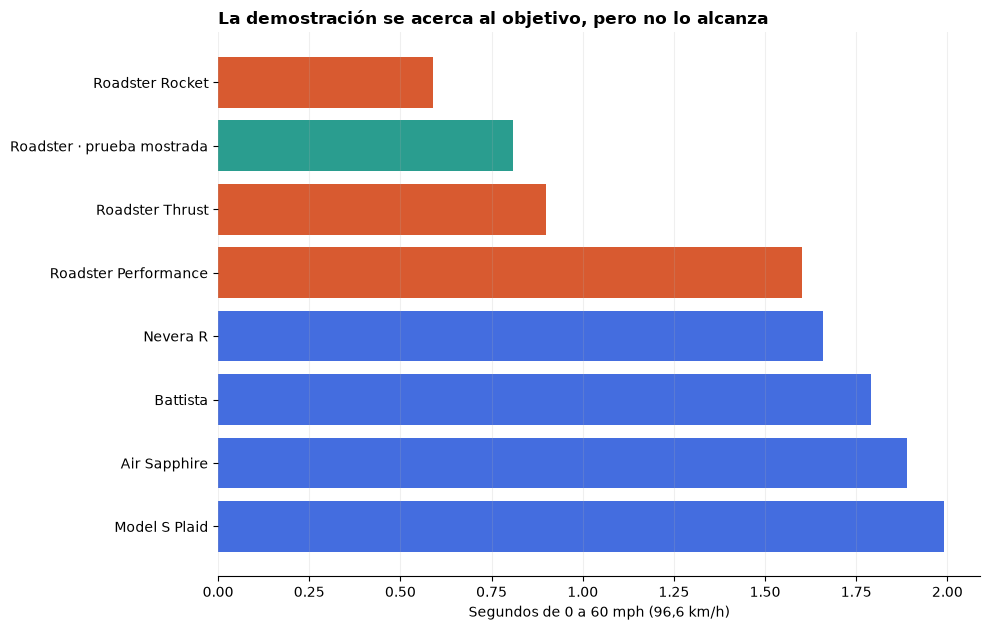

,modelo,comparador,tiempo_0_60_mph_s,aceleracion_media_g,distancia_constante_m,estado_cifra,rollout_descontado
0,Roadster Rocket,<,0.59,4.64,7.91,Objetivo anunciado,No
7,Roadster · prueba mostrada,=,0.81,3.38,10.86,Demostración de Tesla,No indicado
1,Roadster Thrust,<,0.90,3.04,12.07,Objetivo anunciado,No
2,Roadster Performance,<,1.60,1.71,21.46,Objetivo anunciado,No
3,Nevera R,=,1.66,1.65,22.26,Dato del fabricante,No
4,Battista,=,1.79,1.53,24.01,Prueba de homologación del fabricante,No
5,Air Sapphire,=,1.89,1.45,25.35,Especificación final de producción,No
6,Model S Plaid,=,1.99,1.37,26.69,Dato del fabricante,Sí


In [3]:
# convierto los tiempos de 0–60 mph en aceleración media y distancia teórica
velocidad_60_mph_ms = 60 * 1609.344 / 3600
gravedad = 9.80665

aceleracion["aceleracion_media_ms2"] = velocidad_60_mph_ms / aceleracion["tiempo_0_60_mph_s"]
aceleracion["aceleracion_media_g"] = aceleracion["aceleracion_media_ms2"] / gravedad
aceleracion["distancia_constante_m"] = 0.5 * velocidad_60_mph_ms * aceleracion["tiempo_0_60_mph_s"]
aceleracion["es_roadster"] = aceleracion["modelo"].str.startswith("Roadster")

tiempo_demo = float(demostracion.loc[demostracion["indicador"] == "Tiempo mostrado de 0 a 60 mph", "valor"].iloc[0])
demo = pd.DataFrame({
    "modelo": ["Roadster · prueba mostrada"],
    "fabricante": ["Tesla"],
    "propulsion": ["Eléctrica con propulsores"],
    "tiempo_0_60_mph_s": [tiempo_demo],
    "comparador": ["="],
    "estado_cifra": ["Demostración de Tesla"],
    "rollout_descontado": ["No indicado"],
    "fuente": [demostracion.loc[demostracion["indicador"] == "Tiempo mostrado de 0 a 60 mph", "fuente"].iloc[0]],
})
demo["aceleracion_media_ms2"] = velocidad_60_mph_ms / demo["tiempo_0_60_mph_s"]
demo["aceleracion_media_g"] = demo["aceleracion_media_ms2"] / gravedad
demo["distancia_constante_m"] = 0.5 * velocidad_60_mph_ms * demo["tiempo_0_60_mph_s"]
demo["es_roadster"] = True

comparacion = pd.concat([aceleracion, demo], ignore_index=True)
orden = comparacion.sort_values("tiempo_0_60_mph_s", ascending=False)
colores = [color_demo if modelo == "Roadster · prueba mostrada" else color_roadster if es_roadster else color_principal for modelo, es_roadster in zip(orden["modelo"], orden["es_roadster"])]

fig, ax = plt.subplots(figsize=(10, 6.4))
ax.barh(orden["modelo"], orden["tiempo_0_60_mph_s"], color=colores)
ax.set_title("La demostración se acerca al objetivo, pero no lo alcanza", loc="left", weight="bold")
ax.set_xlabel("Segundos de 0 a 60 mph (96,6 km/h)")
ax.set_ylabel("")
ax.grid(axis="x", alpha=0.2)
ax.spines[["top", "right", "left"]].set_visible(False)
plt.tight_layout()
plt.show()

display(
    comparacion.sort_values("tiempo_0_60_mph_s")[[
        "modelo", "comparador", "tiempo_0_60_mph_s", "aceleracion_media_g",
        "distancia_constante_m", "estado_cifra", "rollout_descontado"
    ]].round({"aceleracion_media_g": 2, "distancia_constante_m": 2})
)

### Lectura

El objetivo de menos de 0,59 segundos implica **más de 4,6 g horizontales de media** y **menos de 7,9 metros** recorridos bajo la simplificación constante. La prueba mostrada de 0,81 segundos equivale a unos **3,4 g** y **10,9 metros**.

Para pasar de la demostración al objetivo, Tesla tendría que reducir otro **27%** el tiempo y elevar alrededor de un **37%** la aceleración media. Frente al Nevera R, el objetivo del Rocket recorta aproximadamente un **64%** el tiempo publicado.

No equiparo protocolos. El Model S Plaid descuenta el *rollout* y las cifras del Roadster siguen siendo objetivos o demostraciones del fabricante.

In [4]:
# extraigo las magnitudes centrales que utilizaré en el artículo
rocket = aceleracion.loc[aceleracion["modelo"] == "Roadster Rocket"].iloc[0]
nevera = aceleracion.loc[aceleracion["modelo"] == "Nevera R"].iloc[0]
demo_fila = demo.iloc[0]

reduccion_demo_objetivo = (1 - rocket["tiempo_0_60_mph_s"] / demo_fila["tiempo_0_60_mph_s"]) * 100
aumento_aceleracion_demo_objetivo = (rocket["aceleracion_media_g"] / demo_fila["aceleracion_media_g"] - 1) * 100
reduccion_frente_nevera = (1 - rocket["tiempo_0_60_mph_s"] / nevera["tiempo_0_60_mph_s"]) * 100

resumen_fisica = pd.Series({
    "aceleración media mínima del Rocket (g)": rocket["aceleracion_media_g"],
    "distancia máxima del Rocket con aceleración constante (m)": rocket["distancia_constante_m"],
    "aceleración media de la prueba mostrada (g)": demo_fila["aceleracion_media_g"],
    "distancia de la prueba mostrada con aceleración constante (m)": demo_fila["distancia_constante_m"],
    "reducción de tiempo desde la prueba hasta el objetivo (%)": reduccion_demo_objetivo,
    "aumento de aceleración media necesario (%)": aumento_aceleracion_demo_objetivo,
    "reducción de tiempo frente al Nevera R (%)": reduccion_frente_nevera,
})
display(resumen_fisica.round(2).to_frame("resultado"))

,resultado
aceleración media mínima del Rocket (g),4.64
distancia máxima del Rocket con aceleración constante (m),7.91
aceleración media de la prueba mostrada (g),3.38
distancia de la prueba mostrada con aceleración constante (m),10.86
reducción de tiempo desde la prueba hasta el objetivo (%),27.16
aumento de aceleración media necesario (%),37.29
reducción de tiempo frente al Nevera R (%),64.46


## 3. Lo que enseñó la demostración

La aceleración fue solo una parte del acto. Reúno las lecturas mostradas y las afirmaciones técnicas para no confundirlas con mediciones independientes. Entre ellas aparecen una rampa de 21 metros, 170 grados de inclinación, 2 g de succión, más de 80 kN de empuje, diez propulsores y dos depósitos con 600 litros y unos 250 kilos de aire comprimido.

El dato de 4.700 kilos describe la carga vertical mostrada durante la maniobra. No es el peso declarado del coche. Tampoco puedo convertir los 80 kN en aceleración real porque Tesla no ha publicado la masa del prototipo.

In [5]:
# ordeno la telemetría y comparo las especificaciones de 2017 y 2026
display(demostracion[["indicador", "valor", "unidad", "estado_cifra"]])

fuerza_80kn_toneladas = 80_000 / gravedad / 1_000
print(f"80 kN equivalen al peso de unas {fuerza_80kn_toneladas:.2f} toneladas bajo la gravedad terrestre")

columnas_evolucion = [
    "version", "plazas", "tiempo_0_60_mph_s", "velocidad_maxima_mph",
    "autonomia_millas", "objetivo_produccion", "reserva_usd",
    "disponibilidad", "homologacion_publica"
]
display(evolucion[columnas_evolucion])

,indicador,valor,unidad,estado_cifra
0,Tiempo mostrado de 0 a 60 mph,0.81,segundos,Demostración de Tesla
1,Altura alcanzada en la rampa,21.00,metros,Telemetría mostrada por Tesla
2,Inclinación antes de desprenderse,170.00,grados,Telemetría mostrada por Tesla
3,Carga vertical mostrada,4700.00,kilogramos,Telemetría mostrada por Tesla
4,Pico durante el frenado de la caída,3.30,g,Telemetría mostrada por Tesla
5,Succión máxima anunciada,2.00,g,Afirmación de Tesla
6,Empuje anunciado de los propulsores,80.00,kilonewtons,Límite inferior anunciado
7,Capacidad conjunta de los depósitos,600.00,litros,Afirmación durante la presentación
8,Masa de aire comprimido,250.00,kilogramos,Afirmación durante la presentación
9,Número de propulsores del Rocket,10.00,propulsores,Afirmación de Tesla


80 kN equivalen al peso de unas 8.16 toneladas bajo la gravedad terrestre


,version,plazas,tiempo_0_60_mph_s,velocidad_maxima_mph,autonomia_millas,objetivo_produccion,reserva_usd,disponibilidad,homologacion_publica
0,Prototipo 2017,4,1.90,250.0,620,2020,50000.0,Reserva abierta,Sin determinar
1,Performance 2026,2,1.60,NaN,300,2028,50000.0,Reserva abierta,Orientado a carretera
2,Thrust 2026,2,0.90,NaN,300,2028,250000.0,Lanzamiento limitado,Sin confirmar
3,Rocket 2026,1,0.59,230.0,300,2028,NaN,Solo por invitación,No aprobada


## 4. El coche de 2026 no conserva todas las promesas de 2017

El prototipo de 2017 anunciaba cuatro plazas, 620 millas de autonomía, más de 250 mph y producción en 2020. La nueva gama ofrece como máximo dos plazas; el Rocket se queda en una. Tesla habla ahora de más de 300 millas y más de 230 mph para el Rocket, mientras desplaza el inicio de producción a 2028.

No calculo una caída exacta de autonomía porque «más de 300» es un límite abierto, no un valor cerrado. La comparación muestra cómo ha cambiado el umbral publicitado, no cuánto recorrerá finalmente el coche.

## 5. De una promesa para 2020 a un objetivo para 2028

Tesla presentó la anterior propuesta el 16 de noviembre de 2017 y anunció su llegada para 2020. La demostración de octubre de 2026 mostró otro prototipo y situó el comienzo de la producción en 2028. Trato 2028 como objetivo de la empresa, nunca como predicción propia.

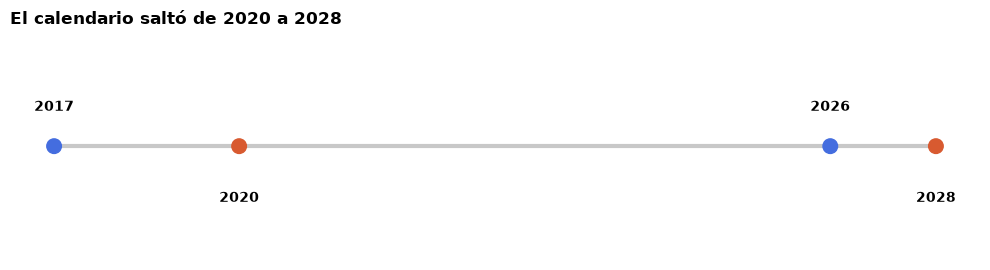

días entre las dos presentaciones: 3.255
diferencia entre el objetivo original y el actual: 8 años


In [6]:
# convierto los hitos en una cronología y calculo las dos esperas relevantes
fecha_presentacion = pd.Timestamp("2017-11-16")
fecha_demostracion = pd.Timestamp("2026-10-15")
objetivo_original = pd.Timestamp("2020-01-01")
objetivo_actual = pd.Timestamp("2028-01-01")

espera_demostracion_dias = (fecha_demostracion - fecha_presentacion).days
retraso_objetivo_anos = objetivo_actual.year - objetivo_original.year

fig, ax = plt.subplots(figsize=(10, 2.8))
ax.hlines(1, hitos["fecha"].min(), hitos["fecha"].max(), color="#c8c8c8", linewidth=3)
ax.scatter(hitos["fecha"], [1] * len(hitos), s=110, color=[color_principal, color_roadster, color_principal, color_roadster], zorder=3)
for i, fila in hitos.iterrows():
    desplazamiento = 0.12 if i % 2 == 0 else -0.16
    ax.text(fila["fecha"], 1 + desplazamiento, fila["fecha"].strftime("%Y"), ha="center", va="center", weight="bold")
ax.set_title("El calendario saltó de 2020 a 2028", loc="left", weight="bold")
ax.set_ylim(0.65, 1.35)
ax.axis("off")
plt.tight_layout()
plt.show()

print(f"días entre las dos presentaciones: {espera_demostracion_dias:,}".replace(",", "."))
print(f"diferencia entre el objetivo original y el actual: {retraso_objetivo_anos} años")

## 6. Un depósito reembolsable también pierde valor

Tesla solicita 50.000 dólares para reservar el Performance. Sus condiciones indican que el dinero no genera intereses ni permanece separado. Planteo una comparación hipotética desde el 16 de noviembre de 2017 hasta el 15 de octubre de 2026.

- La inflación indica cuánto haría falta ahora para conservar el poder de compra inicial.
- Las letras del Tesoro aproximan una alternativa conservadora con reinversión teórica.
- El S&P 500 muestra un escenario histórico con riesgo y sin dividendos, impuestos ni costes.

No afirmo que todos los clientes mantuvieran la reserva durante nueve años ni trato estos escenarios como inversiones equivalentes.

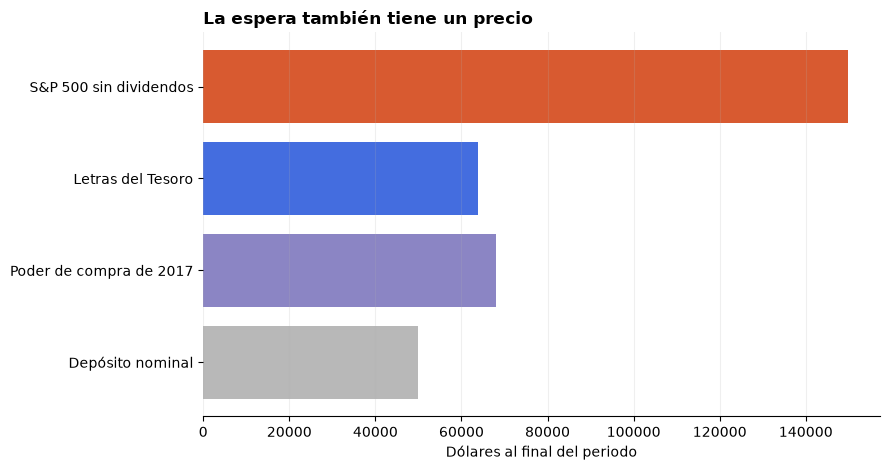

,escenario,valor_2026_usd
0,Depósito nominal,50000.0
1,Poder de compra de 2017,67998.0
2,Letras del Tesoro,63820.0
3,S&P 500 sin dividendos,149751.0


valor real de una devolución nominal de 50.000 dólares, medido en dólares de 2017: 36,766


In [7]:
# convierto las series a número y calculo tres escenarios transparentes
deposito = 50_000.0

ipc["CPIAUCSL"] = pd.to_numeric(ipc["CPIAUCSL"], errors="coerce")
sp500["SP500"] = pd.to_numeric(sp500["SP500"], errors="coerce")
tesoro["DGS3MO"] = pd.to_numeric(tesoro["DGS3MO"], errors="coerce")

ipc = ipc.dropna(subset=["CPIAUCSL"])
sp500 = sp500.dropna(subset=["SP500"])
tesoro = tesoro.dropna(subset=["DGS3MO"])

equivalente_inflacion = deposito * ipc.iloc[-1]["CPIAUCSL"] / ipc.iloc[0]["CPIAUCSL"]
valor_real_deposito = deposito * ipc.iloc[0]["CPIAUCSL"] / ipc.iloc[-1]["CPIAUCSL"]

calendario = pd.DataFrame({"fecha": pd.date_range("2017-11-16", "2026-10-15", freq="D")})
calendario = calendario.merge(
    tesoro.rename(columns={"observation_date": "fecha", "DGS3MO": "tipo"}),
    on="fecha",
    how="left",
)
calendario["tipo"] = calendario["tipo"].ffill().bfill()
calendario["saldo"] = deposito * (1 + calendario["tipo"] / 100 / 365).cumprod()
valor_tesoro = calendario.iloc[-1]["saldo"]
valor_sp500 = deposito * sp500.iloc[-1]["SP500"] / sp500.iloc[0]["SP500"]

escenarios = pd.DataFrame({
    "escenario": ["Depósito nominal", "Poder de compra de 2017", "Letras del Tesoro", "S&P 500 sin dividendos"],
    "valor_2026_usd": [deposito, equivalente_inflacion, valor_tesoro, valor_sp500],
})

fig, ax = plt.subplots(figsize=(9, 4.8))
ax.barh(escenarios["escenario"], escenarios["valor_2026_usd"], color=["#b8b8b8", color_secundario, color_principal, color_roadster])
ax.set_title("La espera también tiene un precio", loc="left", weight="bold")
ax.set_xlabel("Dólares al final del periodo")
ax.set_ylabel("")
ax.grid(axis="x", alpha=0.2)
ax.spines[["top", "right", "left"]].set_visible(False)
plt.tight_layout()
plt.show()

display(escenarios.assign(valor_2026_usd=escenarios["valor_2026_usd"].round(0)))
print(f"valor real de una devolución nominal de 50.000 dólares, medido en dólares de 2017: {valor_real_deposito:,.0f}")

## 7. Resultados, límites y archivos

### Respuesta a la pregunta

La demostración de 0,81 segundos coloca al prototipo fuera de la escala de los eléctricos de producción seleccionados, pero todavía queda un salto cuantificable hasta el objetivo de 0,59. Bajo aceleración constante, el Rocket exigiría más de 4,6 g de media y recorrería menos de 7,9 metros para alcanzar 60 mph.

La maniobra aérea demuestra que Tesla ha construido una máquina capaz de subir casi invertida por una rampa, desprenderse y aterrizar con propulsores. No demuestra la repetibilidad, el precio final, la autonomía real, la homologación ni el inicio de producción en 2028.

La espera añade una dimensión económica: una devolución íntegra conserva los dólares nominales, pero no su poder de compra ni el rendimiento que podrían haber generado.

### Limitaciones

- Comparo cifras de fabricantes con protocolos que pueden diferir.
- La prueba de 0,81 segundos y la telemetría proceden de Tesla, no de una medición independiente.
- Una aceleración media constante simplifica una salida real.
- La selección de coches es editorial, no exhaustiva.
- El Model S Plaid descuenta el *rollout*; Tesla no aclara ese punto para el Roadster.
- Los límites «más de» y «menos de» no son valores exactos.
- El cálculo financiero es hipotético y no representa a todos los reservistas.
- El escenario bursátil excluye dividendos y asumía riesgo.

### Archivos reproducibles

El cuaderno utiliza `aceleracion_fabricantes.csv`, `demostracion_roadster.csv`, `evolucion_roadster.csv`, `hitos_roadster.csv`, `cpi_usa.csv`, `treasury_3m.csv` y `sp500.csv`. En la última celda guardo las tablas derivadas utilizadas en el artículo.

In [8]:
# guardo los resultados comprobados que alimentan el artículo y la interacción
resultados = base / "resultados"
resultados.mkdir(exist_ok=True)

comparacion.sort_values("tiempo_0_60_mph_s").to_csv(
    resultados / "aceleracion_calculada.csv", index=False
)
escenarios.to_csv(resultados / "coste_espera.csv", index=False)
evolucion.to_csv(resultados / "evolucion_roadster.csv", index=False)

resumen = pd.DataFrame({
    "indicador": [
        "g_media_minima_roadster_rocket",
        "distancia_maxima_constante_rocket_m",
        "g_media_prueba_mostrada",
        "distancia_constante_prueba_mostrada_m",
        "reduccion_tiempo_demo_a_objetivo_pct",
        "aumento_aceleracion_demo_a_objetivo_pct",
        "reduccion_tiempo_frente_nevera_pct",
        "dias_entre_presentaciones",
        "anos_entre_objetivos",
        "equivalente_inflacion_usd",
        "valor_tesoro_usd",
        "valor_sp500_sin_dividendos_usd",
        "valor_real_deposito_dolares_2017",
    ],
    "valor": [
        rocket["aceleracion_media_g"],
        rocket["distancia_constante_m"],
        demo_fila["aceleracion_media_g"],
        demo_fila["distancia_constante_m"],
        reduccion_demo_objetivo,
        aumento_aceleracion_demo_objetivo,
        reduccion_frente_nevera,
        espera_demostracion_dias,
        retraso_objetivo_anos,
        equivalente_inflacion,
        valor_tesoro,
        valor_sp500,
        valor_real_deposito,
    ],
})
resumen.to_csv(resultados / "resumen.csv", index=False)
display(resumen.round(2))

,indicador,valor
0,g_media_minima_roadster_rocket,4.64
1,distancia_maxima_constante_rocket_m,7.91
2,g_media_prueba_mostrada,3.38
3,distancia_constante_prueba_mostrada_m,10.86
4,reduccion_tiempo_demo_a_objetivo_pct,27.16
5,aumento_aceleracion_demo_a_objetivo_pct,37.29
6,reduccion_tiempo_frente_nevera_pct,64.46
7,dias_entre_presentaciones,3255.00
8,anos_entre_objetivos,8.00
9,equivalente_inflacion_usd,67998.33
